# Customer Segmentation for an Online Gift Retailer (RFM + K-Means)

**Author:** Daljeet Kaur
**Tools:** Python (pandas, NumPy, matplotlib, seaborn, scikit-learn)
**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) — 541,909 transaction lines from a UK online gift retailer, Dec 2010 – Dec 2011. Many customers are small wholesalers.

## Business problem
The retailer emails every customer the same promotions. Marketing wants to know **who its valuable customers are, who is about to churn, and what to send each group**, so it can stop discounting to customers who would buy anyway and focus win-back spend where it pays.

## Objectives
1. Clean the raw transaction log into reliable customer-level data.
2. Score every customer on **Recency, Frequency and Monetary value (RFM)** and assign business-friendly segments.
3. Validate the segments with **K-means clustering**.
4. Measure **cohort retention** to see how quickly new customers drop off.
5. Recommend a marketing action for each segment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
IMG_DIR, RESULTS_DIR = "../images", "../results"

## 1. Load the raw data

In [2]:
raw = pd.read_excel("../data/online_retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
raw.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 2. Data cleaning
The raw log mixes sales with cancellations, returns, adjustments and guest checkouts. Each rule below is logged so the cleaning is auditable.

In [4]:
log = []
def step(df, mask, reason):
    log.append({"step": reason, "rows_removed": int((~mask).sum()), "rows_left": int(mask.sum())})
    return df[mask]

df = raw.copy()
df = step(df, df.CustomerID.notna(), "Drop rows with no CustomerID (guest checkouts)")
cancel_lines = df[df.InvoiceNo.str.startswith("C")]
df = step(df, ~df.InvoiceNo.str.startswith("C"), "Drop cancellation invoices (InvoiceNo starts with 'C')")
df = step(df, (df.Quantity > 0) & (df.UnitPrice > 0), "Drop zero/negative quantity or price")
non_product = ["POST", "D", "M", "C2", "DOT", "BANK CHARGES", "PADS", "CRUK", "AMAZONFEE"]
df = step(df, ~df.StockCode.isin(non_product), "Drop postage, fees and manual adjustments")
df = step(df, ~df.duplicated(), "Drop exact duplicate lines")

df["CustomerID"] = df.CustomerID.astype(int)
df["Revenue"] = df.Quantity * df.UnitPrice
cleaning_log = pd.DataFrame(log)
cleaning_log

,step,rows_removed,rows_left
0,Drop rows with no CustomerID (guest checkouts),135080,406829
1,Drop cancellation invoices (InvoiceNo starts with 'C'),8905,397924
2,Drop zero/negative quantity or price,40,397884
3,"Drop postage, fees and manual adjustments",1547,396337
4,Drop exact duplicate lines,5187,391150


In [5]:
print(f"Clean rows: {len(df):,}  |  customers: {df.CustomerID.nunique():,}  |  "
      f"invoices: {df.InvoiceNo.nunique():,}  |  revenue: £{df.Revenue.sum():,.0f}")
cancel_value = -(cancel_lines.Quantity * cancel_lines.UnitPrice).sum()
print(f"Cancelled value removed: £{cancel_value:,.0f} "
      f"({cancel_value / (df.Revenue.sum() + cancel_value):.1%} of gross)")

Clean rows: 391,150  |  customers: 4,334  |  invoices: 18,402  |  revenue: £8,737,228
Cancelled value removed: £611,342 (6.5% of gross)


## 3. Business context: revenue trend and markets

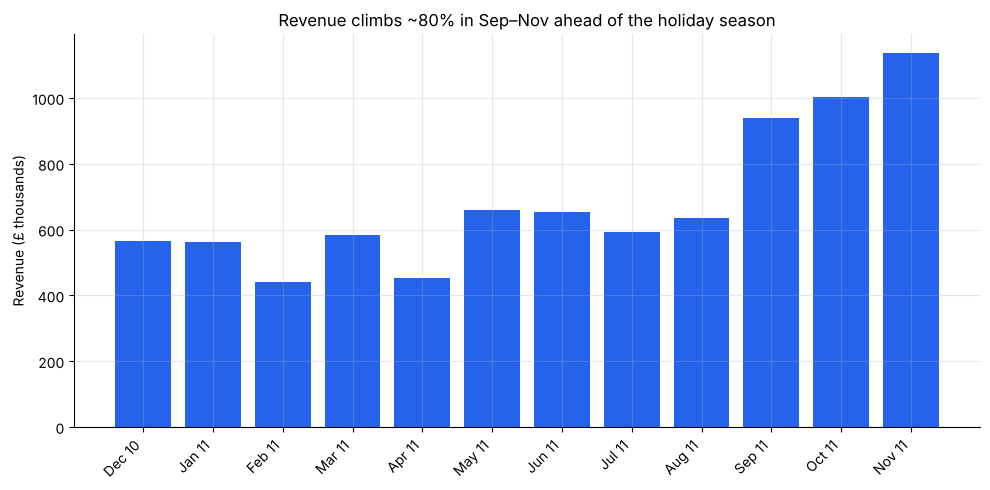

In [6]:
monthly = (df[df.InvoiceDate < "2011-12-01"]            # Dec 2011 is a partial month (data ends 9 Dec)
           .set_index("InvoiceDate").resample("MS")
           .agg({"Revenue": "sum", "CustomerID": "nunique"}))
fig, ax = plt.subplots()
ax.bar(monthly.index.strftime("%b %y"), monthly.Revenue / 1e3, color=BLUE)
ax.set_ylabel("Revenue (£ thousands)")
ax.set_title("Revenue climbs ~80% in Sep–Nov ahead of the holiday season")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_monthly_revenue.png", dpi=150)

In [7]:
country = df.groupby("Country").agg(revenue=("Revenue", "sum"), customers=("CustomerID", "nunique"))
country["revenue_share"] = country.revenue / country.revenue.sum()
country.sort_values("revenue", ascending=False).head(6).round(3)

,revenue,customers,revenue_share
Country,,,
United Kingdom,7242855.32,3916,0.829
Netherlands,283889.34,9,0.032
EIRE,257013.12,3,0.029
Germany,205381.15,94,0.024
France,183801.94,87,0.021
Australia,138103.81,9,0.016


The business is seasonal: Sep–Nov is its peak, with Sep–Nov revenue ~1.8x the Jan–Aug monthly average and November ~2.0x. The UK accounts for about 82% of revenue, so the analysis keeps all countries but the conclusions mainly describe UK customers.

## 4. Build RFM features
- **Recency:** days since the customer's last purchase (snapshot = the day after the last invoice)
- **Frequency:** number of distinct invoices
- **Monetary:** total spend (£)

In [8]:
snapshot = df.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
rfm = (df.groupby("CustomerID")
         .agg(last_purchase=("InvoiceDate", "max"),
              Frequency=("InvoiceNo", "nunique"),
              Monetary=("Revenue", "sum")))
rfm["Recency"] = (snapshot - rfm.last_purchase).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]]
print(f"Snapshot date: {snapshot.date()}  |  customers: {len(rfm):,}")
rfm.describe().round(1)

Snapshot date: 2011-12-10  |  customers: 4,334


,Recency,Frequency,Monetary
count,4334.0,4334.0,4334.0
mean,92.2,4.2,2016.0
std,100.2,7.6,8903.7
min,0.0,1.0,3.8
25%,17.0,1.0,304.2
50%,50.0,2.0,662.6
75%,142.0,5.0,1631.6
max,373.0,206.0,279138.0


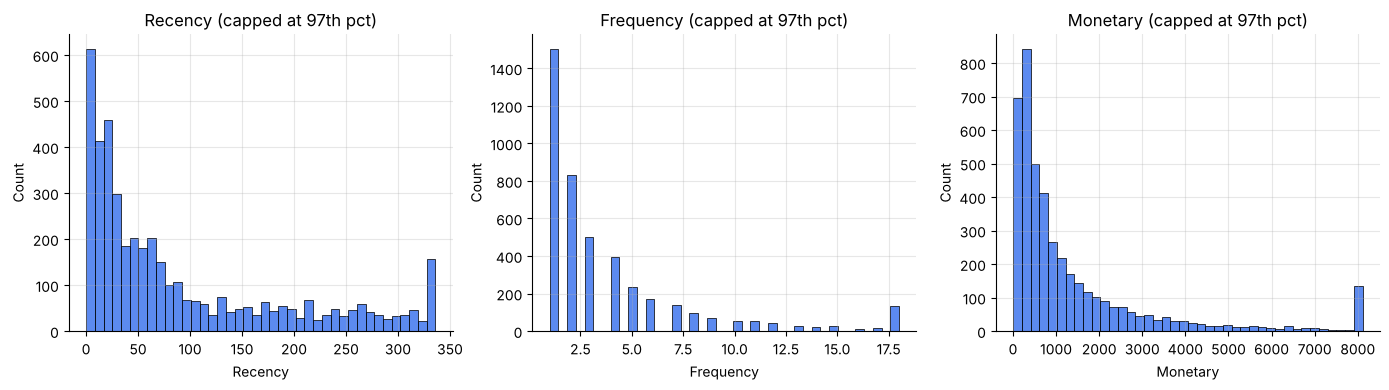

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, rfm.columns):
    sns.histplot(rfm[col].clip(upper=rfm[col].quantile(0.97)), bins=40, ax=ax, color=BLUE)
    ax.set_title(f"{col} (capped at 97th pct)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_rfm_distributions.png", dpi=150)

All three are heavily right-skewed: most customers bought once or twice, while a few wholesalers buy constantly. That is why scoring uses **quintiles** (rank-based) and clustering uses **log-transformed** values.

## 5. RFM scoring and rule-based segments

In [10]:
rfm["R"] = pd.qcut(rfm.Recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)            # recent = high score
rfm["F"] = pd.qcut(rfm.Frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.Monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_score"] = rfm.R.astype(str) + rfm.F.astype(str) + rfm.M.astype(str)

segment_map = {                      # industry-standard R x F grid
    r"[1-2][1-2]": "Hibernating",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5":     "Can't Lose Them",
    r"3[1-2]":     "About to Sleep",
    r"33":         "Need Attention",
    r"[3-4][4-5]": "Loyal Customers",
    r"41":         "Promising",
    r"51":         "New Customers",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]":     "Champions",
}
rfm["Segment"] = (rfm.R.astype(str) + rfm.F.astype(str)).replace(segment_map, regex=True)
rfm.head()

,Recency,Frequency,Monetary,R,F,M,RFM_score,Segment
CustomerID,,,,,,,,
12346,325,1,77183.60,1,1,5,115,Hibernating
12347,2,7,4310.00,5,5,5,555,Champions
12348,75,4,1437.24,2,4,4,244,At Risk
12349,18,1,1457.55,4,1,4,414,Promising
12350,310,1,294.40,1,1,2,112,Hibernating


In [11]:
seg = (rfm.groupby("Segment")
          .agg(customers=("Recency", "size"),
               avg_recency_days=("Recency", "mean"),
               avg_orders=("Frequency", "mean"),
               avg_spend=("Monetary", "mean"),
               revenue=("Monetary", "sum")))
seg["pct_customers"] = seg.customers / seg.customers.sum() * 100
seg["pct_revenue"] = seg.revenue / seg.revenue.sum() * 100
seg = seg.sort_values("revenue", ascending=False)
seg.round(1)

,customers,avg_recency_days,avg_orders,avg_spend,revenue,pct_customers,pct_revenue
Segment,,,,,,,
Champions,655,5.7,12.2,6640.3,4349426.3,15.1,49.8
Loyal Customers,798,33.2,6.4,2775.9,2215159.1,18.4,25.4
At Risk,587,152.6,2.9,1073.4,630092.0,13.5,7.2
Hibernating,1074,217.1,1.1,478.7,514088.6,24.8,5.9
Potential Loyalists,484,16.4,2.0,1022.1,494677.6,11.2,5.7
Can't Lose Them,63,134.3,8.3,2728.5,171893.5,1.5,2.0
About to Sleep,348,52.5,1.1,469.3,163326.1,8.0,1.9
Need Attention,189,51.4,2.3,827.3,156366.8,4.4,1.8
Promising,90,22.9,1.0,287.7,25888.9,2.1,0.3


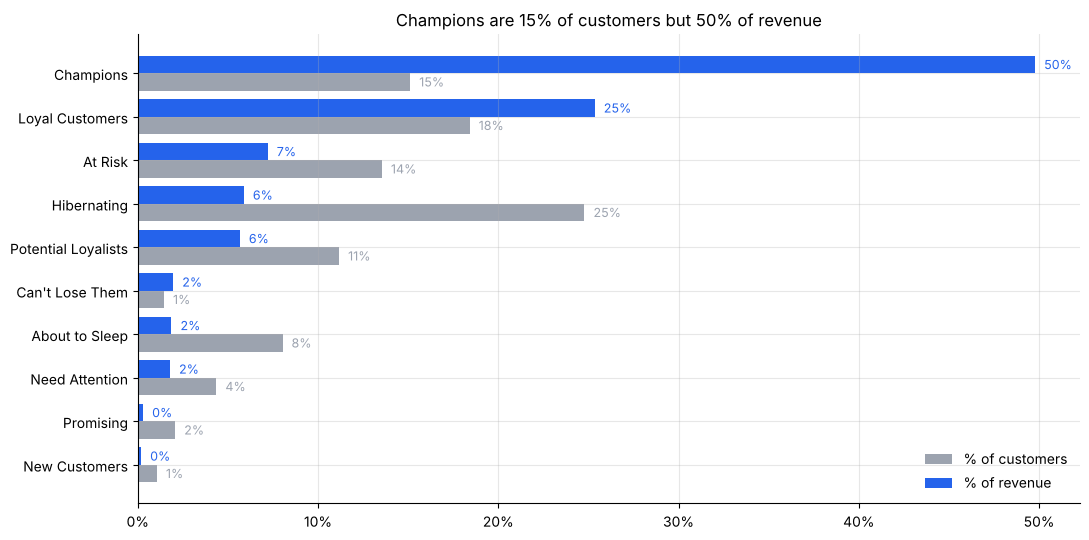

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.5))
order = seg.index
y = np.arange(len(order))
ax.barh(y + 0.2, seg.pct_customers, 0.4, color=GREY, label="% of customers")
ax.barh(y - 0.2, seg.pct_revenue, 0.4, color=BLUE, label="% of revenue")
for i, (c, r) in enumerate(zip(seg.pct_customers, seg.pct_revenue)):
    ax.text(r + 0.5, i - 0.2, f"{r:.0f}%", va="center", fontsize=9, color=BLUE)
    ax.text(c + 0.5, i + 0.2, f"{c:.0f}%", va="center", fontsize=9, color=GREY)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="lower right")
champ = seg.loc["Champions"]
ax.set_title(f"Champions are {champ.pct_customers:.0f}% of customers but {champ.pct_revenue:.0f}% of revenue")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_segments_customers_vs_revenue.png", dpi=150)

In [13]:
at_risk = seg.loc[["At Risk", "Can't Lose Them"]]
print(f"Champions + Loyal: {seg.loc[['Champions', 'Loyal Customers'], 'pct_customers'].sum():.0f}% of customers, "
      f"{seg.loc[['Champions', 'Loyal Customers'], 'pct_revenue'].sum():.0f}% of revenue")
print(f"At Risk + Can't Lose Them: {at_risk.customers.sum():,} customers, "
      f"£{at_risk.revenue.sum():,.0f} lifetime revenue, avg {at_risk.avg_recency_days.mean():.0f}+ days since last order")

Champions + Loyal: 34% of customers, 75% of revenue
At Risk + Can't Lose Them: 650 customers, £801,986 lifetime revenue, avg 143+ days since last order


## 6. Validate with K-means clustering
The RFM grid above is rule-based. As a check, an unsupervised K-means model on log-scaled R, F, M looks for natural groupings in the data.

{2: 0.435, 3: 0.34, 4: 0.336, 5: 0.316, 6: 0.313, 7: 0.309, 8: 0.298}


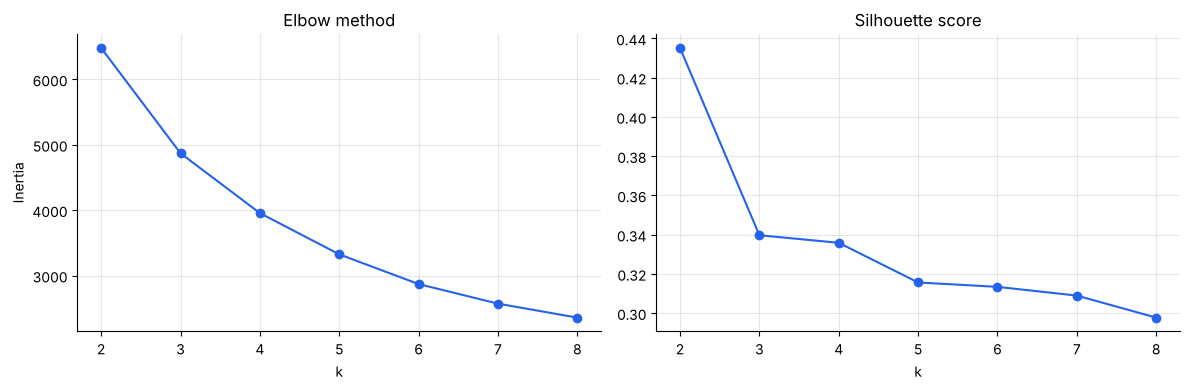

In [14]:
X = StandardScaler().fit_transform(np.log1p(rfm[["Recency", "Frequency", "Monetary"]]))
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=42))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(list(ks), inertia, marker="o", color=BLUE); a1.set_title("Elbow method"); a1.set_xlabel("k"); a1.set_ylabel("Inertia")
a2.plot(list(ks), sil, marker="o", color=BLUE); a2.set_title("Silhouette score"); a2.set_xlabel("k")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_kmeans_elbow_silhouette.png", dpi=150)
print({k: round(s, 3) for k, s in zip(ks, sil)})

The silhouette score is highest at k = 2, but two clusters (good vs bad) aren't actionable. The elbow flattens around **k = 4**, which still has a reasonable silhouette, so k = 4 is used.

In [15]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
rfm["Cluster"] = km.labels_
prof = rfm.groupby("Cluster").agg(customers=("Recency", "size"), Recency=("Recency", "median"),
                                  Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
                                  revenue=("Monetary", "sum"))
# Name clusters by their profile (ranked by median spend; the profile table below shows why each name fits)
rank = prof.Monetary.rank(ascending=False).astype(int)
names = {c: {1: "VIP", 2: "Regular mid-value", 3: "New / developing", 4: "Lost low-value"}[r]
         for c, r in rank.items()}
prof["Cluster_name"] = prof.index.map(names)
prof["pct_revenue"] = prof.revenue / prof.revenue.sum() * 100
rfm["Cluster_name"] = rfm.Cluster.map(names)
prof.sort_values("Monetary", ascending=False).round(1)

,customers,Recency,Frequency,Monetary,revenue,Cluster_name,pct_revenue
Cluster,,,,,,,
3,686,8.0,10.0,3715.4,5593496.4,VIP,64.0
2,1182,52.0,4.0,1357.5,2129199.8,Regular mid-value,24.4
0,820,17.0,2.0,467.3,443648.2,New / developing,5.1
1,1646,173.0,1.0,296.7,570883.2,Lost low-value,6.5


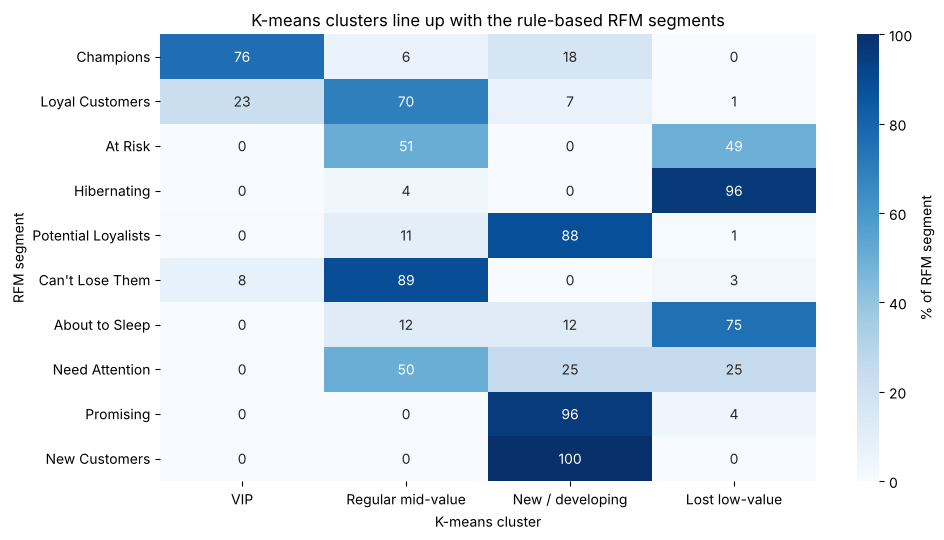

In [16]:
xt = pd.crosstab(rfm.Segment, rfm.Cluster_name, normalize="index") * 100
xt = xt[[c for c in ["VIP", "Regular mid-value", "New / developing", "Lost low-value"] if c in xt.columns]]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.grid(False)
sns.heatmap(xt.loc[seg.index], annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of RFM segment"}, ax=ax)
ax.set_xlabel("K-means cluster"); ax.set_ylabel("RFM segment")
plt.xticks(rotation=0)
ax.set_title("K-means clusters line up with the rule-based RFM segments")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/05_rfm_vs_kmeans.png", dpi=150)

In [17]:
agree = (xt.loc["Champions"].max(), xt.loc["Hibernating"].max())
print(f"{agree[0]:.0f}% of Champions fall in one K-means cluster; {agree[1]:.0f}% of Hibernating customers do too")

76% of Champions fall in one K-means cluster; 96% of Hibernating customers do too


The two methods agree: 76% of Champions fall in the VIP cluster, and 96% of Hibernating customers fall in the lost/low-value cluster. The rule-based segments are kept for marketing because they are easier to explain to stakeholders, and K-means confirms they reflect real structure in the data.

## 7. Cohort retention
Customers are grouped by the month of their first purchase. The heatmap shows the share still buying N months later. December 2011 is excluded because the data stops on 9 Dec, so that month is incomplete.

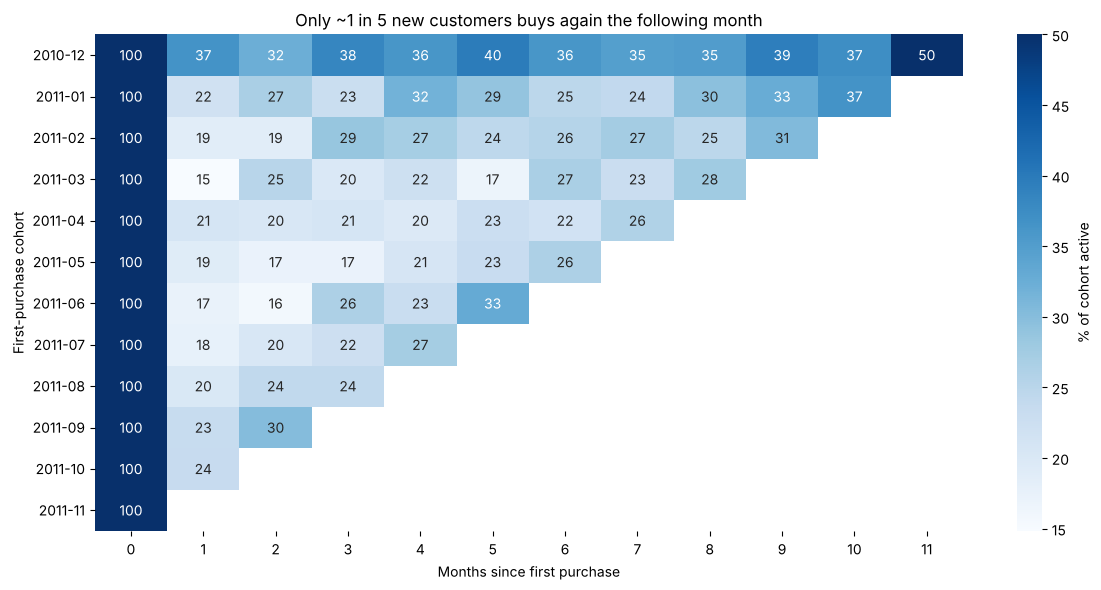

In [18]:
coh = df[df.InvoiceDate < "2011-12-01"].copy()
coh["order_month"] = coh.InvoiceDate.dt.to_period("M")
coh["cohort"] = coh.groupby("CustomerID").order_month.transform("min")
coh["period"] = (coh.order_month - coh.cohort).apply(lambda x: x.n)
cohort = coh.groupby(["cohort", "period"]).CustomerID.nunique().unstack()
retention = cohort.div(cohort[0], axis=0)
retention = retention.loc[:, :11]
fig, ax = plt.subplots(figsize=(12, 6))
ax.grid(False)
sns.heatmap(retention * 100, annot=True, fmt=".0f", cmap="Blues", vmax=50,
            cbar_kws={"label": "% of cohort active"}, ax=ax)
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("First-purchase cohort")
ax.set_title("Only ~1 in 5 new customers buys again the following month")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/06_cohort_retention.png", dpi=150)

In [19]:
m1 = retention[1].dropna()
print(f"Month-1 retention: median {m1.median():.0%} (range {m1.min():.0%}–{m1.max():.0%})")
print(f"Dec-2010 cohort still active in month 11: {retention.loc['2010-12', 11]:.0%}")

Month-1 retention: median 20% (range 15%–37%)
Dec-2010 cohort still active in month 11: 50%


Most new customers don't come back the next month (median month-1 retention 20%). The **Dec 2010 cohort** is different: these are existing wholesale customers seen for the first time when the data starts, and about half are still buying in month 11. That shows how valuable a retained wholesale account is.

## 8. Save results

In [20]:
rfm.reset_index().to_csv(f"{RESULTS_DIR}/customer_segments.csv", index=False)
seg.round(2).to_csv(f"{RESULTS_DIR}/segment_summary.csv")
prof.round(2).to_csv(f"{RESULTS_DIR}/kmeans_cluster_profiles.csv")
(retention * 100).round(1).to_csv(f"{RESULTS_DIR}/cohort_retention.csv")
cleaning_log.to_csv(f"{RESULTS_DIR}/cleaning_log.csv", index=False)
print("Saved customer_segments.csv (one row per customer, ready to load into the CRM / email tool)")

Saved customer_segments.csv (one row per customer, ready to load into the CRM / email tool)


## Recommended action by segment

| Segment | Who they are | Action |
|---|---|---|
| **Champions** | Bought recently, often, high spend | VIP program, early access to new collections, referral asks. **No discounts needed.** |
| **Loyal Customers** | Frequent, slightly less recent | Loyalty tiers, bundles, cross-sell into new categories |
| **Potential Loyalists / New** | Recent but few orders | Onboarding series and a second-order incentive within 30 days |
| **At Risk / Can't Lose Them** | Used to buy often, silent for ~4+ months | Personal outreach for wholesale accounts, win-back offer, "what changed?" survey |
| **Need Attention / About to Sleep** | Average customers going quiet | Limited-time offer timed before the Sep–Nov peak |
| **Hibernating** | Old, rare, low spend | Low-cost seasonal email only. Don't spend paid media here. |

**Expected impact:** replacing blanket promotions with segment-specific ones cuts discount cost on Champions, who would buy anyway. It also focuses win-back effort on the At Risk groups, which hold a large share of historical revenue.